In [2]:
from typing import Callable
import numpy as np

## Question 1

In [3]:
def tGC(H: Callable[[np.ndarray], np.ndarray], g: np.ndarray, delta: float, return_boundary=False):
    # Optional boundary flag for TR (Remark 6.16); old calls still return a vector.
    if delta <= 0:
        raise ValueError("delta must be greater than 0.")

    v_n = np.zeros(g.shape)
    r_n = -g.copy()
    r_0_norm = np.linalg.norm(r_n)
    norm_r_n = r_0_norm
    p_n = r_n.copy()
    n = 0

    while n < len(g):  # Dimension-based inner cap suggested in Remark 6.17.
        
        if norm_r_n <= r_0_norm * np.min([r_0_norm, 0.1]):  # Algorithm 6.2 / eq. (6.21).
            print(f"Tolerance reached in {n} iterations: {norm_r_n} < {r_0_norm * np.min([r_0_norm, 0.1])}")
            return (v_n, False) if return_boundary else v_n
        
        norm_p_n_squared = np.dot(p_n, p_n)
        pn_vn = np.dot(p_n, v_n)
        v_n_norm = np.linalg.norm(v_n)

        a = norm_p_n_squared
        b = 2.0 * pn_vn
        c = np.min([0.0, (v_n_norm - delta) * (v_n_norm + delta)])

        roots = np.roots([a, b, c])
        t_n_plus = np.max(roots)
        
        Hp = H(p_n)
        pHp = np.dot(p_n, Hp)

        if norm_r_n**2 >= pHp * t_n_plus:
            print("Hit the boundary")
            step = v_n + t_n_plus * p_n
            return (step, True) if return_boundary else step

        t_n = norm_r_n**2 / pHp
        v_n = v_n + t_n * p_n
        next_r = r_n - t_n * Hp
        next_r_norm = np.linalg.norm(next_r)

        p_n = next_r + (next_r_norm**2 / norm_r_n**2) * p_n
        r_n = next_r
        norm_r_n = next_r_norm
        n = n + 1

    return (v_n, False) if return_boundary else v_n  # Return the approximation at the cap.


In [4]:
# 1-D tests
# f(x) = x**2 , x = 0, expected solution 0
x_0 = np.array([0.0])
H_test = lambda p: 2.0 * p
g_test = 2 * x_0
delta_test = 1.0

result = tGC(H_test, g_test, delta_test)
print("Aprroximate minimizer:", result)

# f(x) = x**2 , x = 0.5, expected solution -0.5
x_0 = np.array([0.5])
H_test = lambda p: 2.0 * p
g_test = 2 * x_0
delta_test = 2.0

result = tGC(H_test, g_test, delta_test)
print("Aprroximate minimizer:", result)

# f(x) = x**2 , x = 1, expected solution -1
x_0 = np.array([1.0])
H_test = lambda p: 2.0 * p
g_test = 2 * x_0
delta_test = 2.0

result = tGC(H_test, g_test, delta_test)
print("Aprroximate minimizer:", result)

# f(x) = x**2 , x = 1, expected solution -delta
x_0 = np.array([1.0])
H_test = lambda p: 2.0 * p
g_test = 2 * x_0
delta_test = 1e-5

result = tGC(H_test, g_test, delta_test)
print("Aprroximate minimizer:", result)

Tolerance reached in 0 iterations: 0.0 < 0.0
Aprroximate minimizer: [0.]
Aprroximate minimizer: [-0.5]
Aprroximate minimizer: [-1.]
Hit the boundary
Aprroximate minimizer: [-1.e-05]


In [7]:
# 2-D tests
# f(x, y) = x, x_0 = [1.0, 1.0], expected sol [-delta,0]
x_0 = np.array([1.0, 1.0])

A = np.array([[0.0, 0.0], 
              [0.0, 0.0]])
H_test = lambda p: A @ p

g_test = np.array([1.0, 0.0])
delta_test = 100.0

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)


# f(x, y) = x**2 + y**2, x_0 = [0.0, 0.0], expected sol [0,0]
x_0 = np.array([0.0, 0.0])

A = np.array([[2.0, 0.0], 
              [0.0, 2.0]])
H_test = lambda p: A @ p

g_test = np.array([0.0, 0.0])
delta_test = 1.0

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)

# f(x, y) = x**2 - y**2, x_0 = [0.0, 0.0], expected sol [0,0]
x_0 = np.array([0.0, 0.0])

A = np.array([[2.0, 0.0], 
              [0.0, -2.0]])
H_test = lambda p: A @ p

g_test = np.array([0.0, 0.0])
delta_test = 1.0

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)

# f(x, y) = x**2 - y**2, x_0 = [0.1, 0.1], expected sol [-sqrt(2)/2,sqrt(2)/2]
x_0 = np.array([0.1, 0.1])


A = np.array([[2.0, 0.0], 
              [0.0, -2.0]])
H_test = lambda p: A @ p

g_test = np.array([0.2, -0.2])
delta_test = 1.0

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)

# 2-D tests
# f(x, y) = 0.5*x**2 + 50*y**2, x_0 = [0.7, -0.7]
x_0 = np.array([0.7, -0.7])

A = np.array([[1.0, 0.0], 
              [0.0, 100.0]])
H_test = lambda p: A @ p

g_test = np.array([0.7, -70.0])
delta_test = 1.0

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)

# the stopping criteria is norm_r_n <= r_0_norm * np.min([r_0_norm, 0.1]) = 70.003 * 0.1 = 7 
# the minimizer is almost [0.7, 0.0] whith gradient norm 0.7 < 7

Hit the boundary
Approximate minimizer: [-100.    0.]
Tolerance reached in 0 iterations: 0.0 < 0.0
Approximate minimizer: [0. 0.]
Tolerance reached in 0 iterations: 0.0 < 0.0
Approximate minimizer: [0. 0.]
Hit the boundary
Approximate minimizer: [-0.70710678  0.70710678]
Tolerance reached in 1 iterations: 0.6930339560998371 < 7.000349991250437
Approximate minimizer: [-0.00700069  0.7000693 ]


In [8]:
# 3-D tests
# Can we find the exact solution?
# f(x, y) = 1e-5 * x^2 + 100 * y^2 + 1e5 * z^2, expected sol -x_0 

H_diag = np.array([2e-5, 200.0, 2e-3])
H_test = lambda p: H_diag * p

x_0 = 1.0 / H_diag          # = [5e4, 5e-3, 5e2]
g_test = H_diag * x_0       # = [1, 1, 1]
delta_test = 1e5            # > ||x_0|| ≈ 5e4, Newton step is in the ball

result = tGC(H_test, g_test, delta_test)
print("Approximate minimizer:", result)

Approximate minimizer: [-5.00000000e+04 -5.00029753e-03 -5.00000000e+02]


## Question 3

In [9]:
def f(x):
    r = (A @ x)**2 - y**2
    return np.dot(r, r) / (4 * n)


def grad_f(x):
    z = A @ x
    return A.T @ ((z**2 - y**2) * z) / n


def hess_f(x):
    w = 3 * (A @ x)**2 - y**2
    return lambda v: A.T @ (w * (A @ v)) / n

## Question 4


In [11]:
import matplotlib.pyplot as plt
from time import perf_counter
from contextlib import redirect_stdout

rng = np.random.default_rng(99)
n = 200
m = 6 * n
sigma = 1e-3
A = rng.uniform(size=(m, n)) / np.sqrt(n)
x_true = rng.standard_normal(n)
y = np.abs(A @ x_true) + sigma * rng.standard_normal(m)
x0 = rng.standard_normal(n)

Matplotlib is building the font cache; this may take a moment.


In [12]:
def optimize(f, grad_f, hess_f, x0, alpha_bar, rho_accept, method="TR-tCG",
             tol=1e-6,       # Stricter than HMW1: its tolerance stopped too early on phase retrieval
             time_limit=180): # 3-minute time limit

    if alpha_bar <= 0 or not 0 < rho_accept < 0.25:
        raise ValueError("Require alpha_bar > 0 and 0 < rho_accept < 1/4 (Algorithms 3.2, 6.1)")
    x = x0.copy()
    delta_max = np.sqrt(len(x0))  # See Remark 6.1
    delta = delta_max / 8         # See Remark 6.1
    history, iterates = [],[]
    start = perf_counter()
    fx = f(x)
    g = grad_f(x)
    target = tol * np.linalg.norm(g)  # Same as HMW1

    while True:
        history.append([fx, np.linalg.norm(g), perf_counter() - start])
        iterates.append(x.copy())
        if not np.isfinite(fx) or not np.all(np.isfinite(g)):
            status = "non-finite value"
            break
        if np.linalg.norm(g) <= target:
            status = "gradient_tolerance"
            break
        if perf_counter() - start >= time_limit:
            status = "time_limit"
            break

        if method == "TR-tCG":
            H = hess_f(x)
            with redirect_stdout(None): # Suppress tGC output (for timing purposes)
                v, boundary = tGC(H, g, delta, return_boundary=True)  # Remark 6.16
            predicted = -np.dot(g, v) - 0.5 * np.dot(v, H(v)) # m_k(0) - m_k(v) in the notes (see exercise 6.3)
            if not np.isfinite(predicted) or predicted <= 0:
                raise RuntimeError("Invalid predicted reduction")
            trial = x + v
            trial_f = f(trial)
            rho = (fx - trial_f) / predicted if np.isfinite(trial_f) else -np.inf
            if rho < 0.25:  # Algorithm 6.1, eq. (6.5)
                delta *= 0.25  # Algorithm 6.1, eq. (6.5)
            elif rho > 0.75 and boundary:  # Algorithm 6.1, eq. (6.5)
                delta = min(2 * delta, delta_max)  # Algorithm 6.1, eq. (6.5)
            if delta == 0:  # Detect floating-point underflow (no arbitrary radius cutoff)
                raise RuntimeError("Trust-region radius became too small")
            accepted = rho > rho_accept  # Algorithm 6.1, eq. (6.4)
        else:
            alpha = alpha_bar  # Algorithm 3.2
            while True:
                trial = x - alpha * g
                trial_f = f(trial)
                if np.isfinite(trial_f) and trial_f <= fx - 1e-4 * alpha * np.dot(g, g):  # c=1e-4: Algorithm 3.2
                    break
                alpha *= 0.5  # Typical contraction factor (alpha <-- rho*alpha, rho = 0.5)
                if alpha == 0:
                    raise RuntimeError("Line-search step underflowed")
                if perf_counter() - start >= time_limit:
                    return np.array(iterates), np.array(history), "time_limit"
            accepted = True

        if accepted:
            x, fx = trial, trial_f
            g = grad_f(x)

    return np.array(iterates), np.array(history), status

TR-tCG: gradient_tolerance, 13 iterations, 0.020 s
f = 1.285e-06, gradient norm = 7.097e-10, error = 1.860e-03
GD: gradient_tolerance, 28178 iterations, 1.766 s
f = 1.285e-06, gradient norm = 2.498e-08, error = 1.860e-03


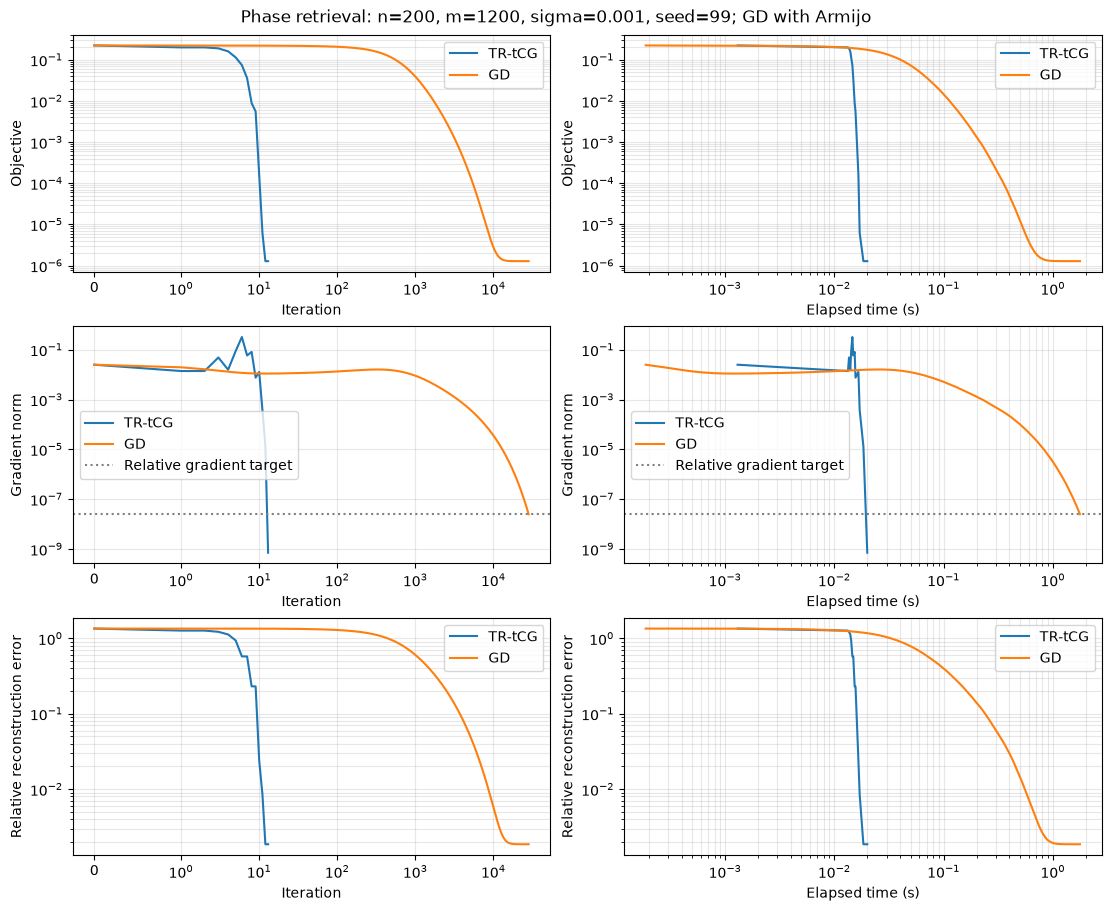

In [13]:
tol = 1e-6 
alpha_bar = 1.0  # Algorithm 3.2; alppha_bar > 0
rho_accept = 0.1  # Free parameter in (0, 1/4), Algorithm 6.1
target = tol * np.linalg.norm(grad_f(x0))
results = {}

for method in ["TR-tCG", "GD"]:
    X, history, status = optimize(f, grad_f, hess_f, x0, alpha_bar, rho_accept, method,
                                  tol=tol)
    error = np.minimum(np.linalg.norm(X - x_true, axis=1),
                       np.linalg.norm(X + x_true, axis=1)) / np.linalg.norm(x_true)
    results[method] = (history, error)
    print(f"{method}: {status}, {len(history) - 1} iterations, {history[-1, 2]:.3f} s")
    print(f"f = {history[-1, 0]:.3e}, gradient norm = {history[-1, 1]:.3e}, error = {error[-1]:.3e}")

fig, axes = plt.subplots(3, 2, figsize=(11, 9), constrained_layout=True)
labels = ["Objective", "Gradient norm", "Relative reconstruction error"]
for method, (history, error) in results.items():
    for row, values in enumerate([history[:, 0], history[:, 1], error]):
        axes[row, 0].semilogy(np.arange(len(history)), values, label=method)
        axes[row, 1].loglog(history[:, 2], values, label=method)

for row in range(3):
    axes[row, 0].set_xscale("symlog", linthresh=1)
    for col in range(2):
        axes[row, col].set_xlabel("Iteration" if col == 0 else "Elapsed time (s)")
        axes[row, col].set_ylabel(labels[row])
        axes[row, col].grid(True, which="both", alpha=0.3)
        if row == 1:
            axes[row, col].axhline(target, color="gray", linestyle=":", label="Relative gradient target")
        axes[row, col].legend()
fig.suptitle("Phase retrieval: n=200, m=1200, sigma=0.001, seed=99; GD with Armijo")
plt.show()

Reconstruction errors are computed after the solvers finish, and include the global sign ambiguity. Log axes reveal changes across orders of magnitude; the iteration axis retains zero using symlog. Noise prevents exact recovery, and a small gradient alone does not guarantee a global minimum.
